# Informe de evaluación de modelos
## Detección de burnout alto en desarrolladores
**Estudiante:** Daiana Sepúlveda  
**Pre-entrega:** Evaluación y comparación del pipeline — M9

Se continúa el proyecto de las entregas anteriores sobre desgaste profesional y estrés en desarrolladores. Se comparan Regresión Logística y Random Forest para identificar registros con **burnout alto** frente a niveles bajo o medio.

En Colab, seleccionar **Entorno de ejecución → Ejecutar todas**. El dataset se carga desde GitHub; también se puede usar una copia local junto al notebook.

## 1. Datos y preparación
Se utiliza el mismo dataset de la [entrega 4](https://github.com/DaianaSep/pre-entrega-4). Se mantienen sus filtros: trabajo diario mayor que cero, estrés no negativo y diferencia entre edad y experiencia de al menos 18 años. Se eliminan duplicados exactos y registros sin una etiqueta válida.

La clase positiva es `High` (1); `Low` y `Medium` forman la clase 0. Esta agrupación permite evaluar una alerta de burnout alto con curvas ROC binarias. Se conserva `stress_level` como predictor, suponiendo que está disponible al generar la alerta; la evaluación no demuestra diagnóstico clínico ni capacidad de anticipar burnout futuro.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, average_precision_score)

archivo = Path('developer_burnout_dataset_7000.csv')
url = 'https://raw.githubusercontent.com/DaianaSep/pre-entrega-4/333a63e828d03e5be22c8ffa6e0e35a33d2721e4/developer_burnout_dataset_7000.csv'
df = pd.read_csv(archivo if archivo.exists() else url)
filtro = ((df.daily_work_hours > 0) & (df.stress_level >= 0)
          & ((df.age - df.experience_years) >= 18))
datos = df.loc[filtro].drop_duplicates().copy()
datos = datos[datos.burnout_level.isin(['Low', 'Medium', 'High'])].copy()
X = datos.drop(columns='burnout_level')
y = (datos.burnout_level == 'High').astype(int)
print(f'Registros originales: {len(df)} | Registros utilizados: {len(datos)}')
display(pd.DataFrame({'Cantidad': y.value_counts().sort_index(),
                      'Porcentaje': y.value_counts(normalize=True).sort_index().mul(100)})
        .rename(index={0: 'Bajo o medio (0)', 1: 'Alto (1)'}).round(2))

Registros originales: 7000 | Registros utilizados: 4444


Matplotlib is building the font cache; this may take a moment.


,Cantidad,Porcentaje
burnout_level,,
Bajo o medio (0),3273,73.65
Alto (1),1171,26.35


## 2. Entrenamiento comparativo
Se reserva el 20 % para prueba, con partición estratificada y semilla 42. Ambos modelos usan exactamente los mismos registros. La imputación por mediana y el escalado se ajustan **solo con entrenamiento**, dentro de cada pipeline, para evitar fuga de información. Todos los predictores son numéricos; únicamente se codifica la variable objetivo.

Se utiliza Regresión Logística como modelo base y Random Forest con 200 árboles como ensamble. Se aplica `class_weight='balanced'` a ambos para considerar el desbalance. Se mantienen configuraciones fijas y un umbral de 0,5, sin elegir hiperparámetros a partir del test.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
modelos = {
    'Regresión Logística': Pipeline([
        ('imputacion', SimpleImputer(strategy='median')),
        ('escalado', StandardScaler()),
        ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))]),
    'Random Forest': Pipeline([
        ('imputacion', SimpleImputer(strategy='median')),
        ('modelo', RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                          random_state=42, n_jobs=-1))])
}
predicciones, probabilidades, filas = {}, {}, []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)
    probabilidades[nombre] = modelo.predict_proba(X_test)[:, 1]
    filas.append({'Modelo': nombre,
                  'Precision': precision_score(y_test, predicciones[nombre], zero_division=0),
                  'Recall': recall_score(y_test, predicciones[nombre], zero_division=0),
                  'F1-Score': f1_score(y_test, predicciones[nombre], zero_division=0),
                  'AUC-ROC': roc_auc_score(y_test, probabilidades[nombre])})
resultados = pd.DataFrame(filas).set_index('Modelo')
print(f'Entrenamiento: {len(y_train)} | Prueba: {len(y_test)}')
display(resultados.round(4))

Entrenamiento: 3555 | Prueba: 889


,Precision,Recall,F1-Score,AUC-ROC
Modelo,,,,
Regresión Logística,0.9213,1.0,0.959,0.9996
Random Forest,1.0000,1.0,1.000,1.0000


## 3. Matrices de confusión
Las filas indican la clase real y las columnas la predicción. Un **falso negativo** es un registro con burnout alto clasificado como bajo o medio. Un **falso positivo** es una alerta de burnout alto en un registro bajo o medio.

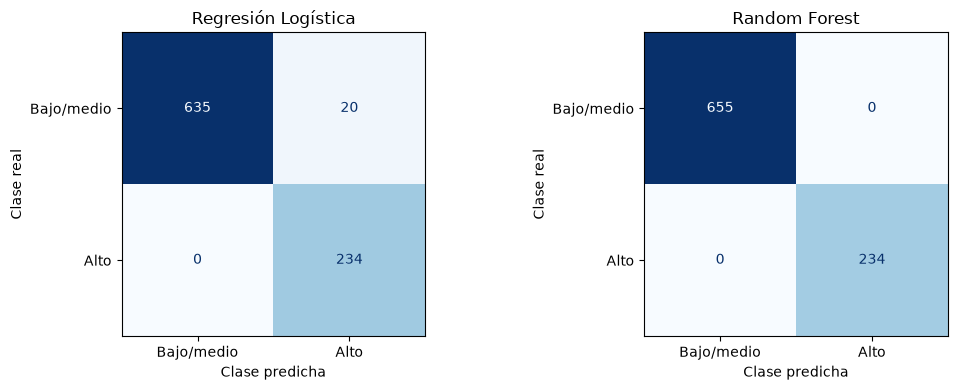

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nombre, pred) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
        display_labels=['Bajo/medio', 'Alto'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
plt.tight_layout()
plt.show()

## 4. Curvas ROC comparadas
El eje horizontal representa la tasa de falsos positivos y el vertical la tasa de verdaderos positivos (recall). El AUC resume la capacidad de ordenar los registros positivos por encima de los negativos: 0,5 corresponde a una discriminación aleatoria y 1 a una discriminación perfecta. No representa el porcentaje de predicciones correctas.

Regresión Logística: AUC = 0.9996.
Random Forest: AUC = 1.0000.


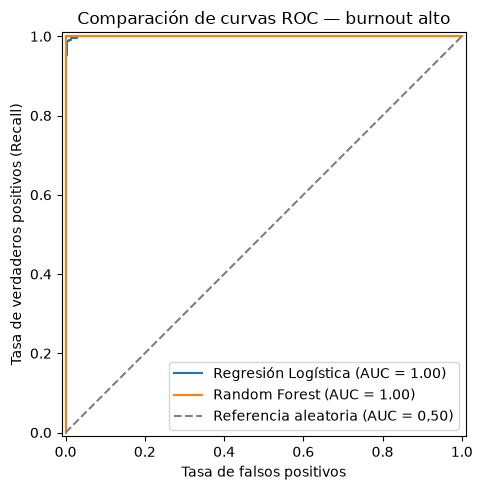

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, prob in probabilidades.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Referencia aleatoria (AUC = 0,50)')
ax.set(title='Comparación de curvas ROC — burnout alto',
       xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos (Recall)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
for nombre, fila in resultados.iterrows():
    print(f'{nombre}: AUC = {fila["AUC-ROC"]:.4f}.')

### Complemento breve: Precision-Recall
Esta curva permite observar el equilibrio entre la confiabilidad de las alertas (precision) y la proporción de casos altos detectados (recall), especialmente útil cuando existe desbalance. La línea horizontal indica la proporción de positivos en test. AP resume la curva; no reemplaza el F1 al umbral elegido.

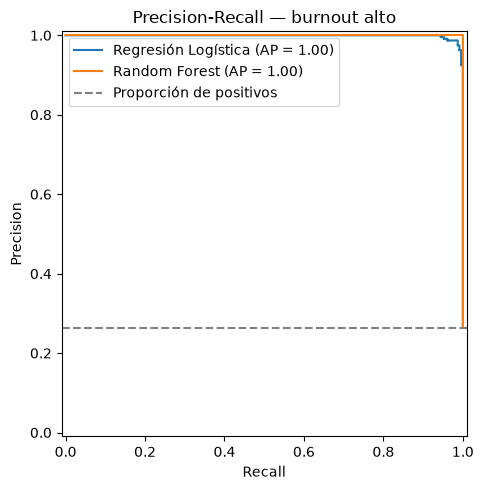

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, prob in probabilidades.items():
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=nombre, ax=ax)
ax.axhline(y_test.mean(), linestyle='--', color='gray', label='Proporción de positivos')
ax.set(title='Precision-Recall — burnout alto', xlabel='Recall', ylabel='Precision')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

## 5. Conclusión técnica y de negocio
La **precision** expresa qué proporción de las alertas corresponde a burnout alto. El **recall** expresa qué proporción de los casos altos se detecta. El **F1-Score** resume su equilibrio; por eso la selección no se basa solo en accuracy ni en pequeñas diferencias de AUC.

Para una alerta preventiva, se considera más crítico el falso negativo: omitir un caso alto puede retrasar una intervención de apoyo. Los falsos positivos también tienen costo, porque requieren revisión y pueden generar alertas innecesarias. Se recomienda el modelo con mayor F1 en esta comparación, revisando explícitamente su recall y sus errores antes de considerar su implementación.

In [6]:
elegido = resultados.sort_values(['F1-Score', 'Recall'], ascending=False).index[0]
r = resultados.loc[elegido]
from sklearn.metrics import confusion_matrix
vn, fp, fn, vp = confusion_matrix(y_test, predicciones[elegido], labels=[0, 1]).ravel()
display(Markdown(
    f'**Recomendación: {elegido}.** En el conjunto de prueba obtuvo '
    f'precision **{r["Precision"]:.3f}**, recall **{r["Recall"]:.3f}**, '
    f'F1 **{r["F1-Score"]:.3f}** y AUC **{r["AUC-ROC"]:.3f}**. '
    f'Detectó **{vp} de {vp + fn}** casos de burnout alto, '
    f'con **{fn} falsos negativos** y **{fp} falsos positivos**. '
    'La recomendación se limita a esta muestra y a una alerta con revisión humana. '
    'Antes de implementarlo, sería necesario validar con datos nuevos y confirmar '
    'cómo se construyó la etiqueta de burnout, especialmente su relación con el estrés.'))

**Recomendación: Random Forest.** En el conjunto de prueba obtuvo precision **1.000**, recall **1.000**, F1 **1.000** y AUC **1.000**. Detectó **234 de 234** casos de burnout alto, con **0 falsos negativos** y **0 falsos positivos**. La recomendación se limita a esta muestra y a una alerta con revisión humana. Antes de implementarlo, sería necesario validar con datos nuevos y confirmar cómo se construyó la etiqueta de burnout, especialmente su relación con el estrés.

**Lectura de los resultados obtenidos:** Random Forest alcanzó precision, recall, F1 y AUC de 1,000 en esta partición. Regresión Logística alcanzó recall de 1,000, precision de 0,921 y F1 de 0,959. Ambos detectaron todos los positivos del test, pero Random Forest evitó las falsas alertas de la regresión logística. Por eso se recomienda Random Forest para este ejercicio.

Los valores perfectos corresponden únicamente a este test: no garantizan el mismo desempeño en otros datos. Pueden reflejar reglas muy claras en la construcción de las etiquetas. No se dispone aquí de documentación que permita verificar esa construcción; por eso se requiere revisar el origen del dataset antes de usarlo en una implementación real.